# Phase 3 - Review Sentiment Analysis
**TF-IDF + Logistic Regression** (compared with Naive Bayes and Linear SVM)

### What this notebook does
Labels each customer review **positive / neutral / negative**. It powers the coloured badge on
the product page and the admin 'negative reviews' queue.

### Pipeline
1. Load 23,486 reviews (*Women's Clothing E-Commerce Reviews*)
2. **Derive labels from the star rating**: 4-5 -> positive, 3 -> neutral, 1-2 -> negative
3. Merge title + body, **TF-IDF** (10k features, 1-2 grams)
4. Handle class imbalance with **balanced class weights** (not SMOTE - it scored lower)
5. Compare **Logistic Regression / Naive Bayes / Linear SVM**, keep the best macro-F1

> **Why class weights over SMOTE?** SMOTE scored macro-F1 **0.617** vs **0.633** for class
> weighting, and class weighting keeps the full TF-IDF signal. Both were tested.


In [1]:
#@title 0  Install dependencies { display-mode: "form" }
!pip -q install pandas numpy scikit-learn matplotlib
print("deps ready")


deps ready


## 1. Load the data


In [2]:
#@title 1.1  Load the dataset (Colab-ready) { display-mode: "form" }
import os

CSV_NAME = "Womens Clothing E-Commerce Reviews.csv"
LOCAL_PATH = "data/raw/sentiment/Womens Clothing E-Commerce Reviews.csv"   # used if you cloned the repo into Colab

PATH = None

# (a) already in the Colab working dir?
if os.path.exists(CSV_NAME):
    PATH = CSV_NAME
# (b) repo layout present?
elif os.path.exists(LOCAL_PATH):
    PATH = LOCAL_PATH

# (c) otherwise upload it (Colab file picker)
if PATH is None:
    try:
        from google.colab import files
        print('Please upload:', CSV_NAME)
        up = files.upload()
        PATH = list(up.keys())[0]
    except Exception:
        raise FileNotFoundError(
            'Dataset not found. Put ' + CSV_NAME + ' next to this notebook, or mount Drive.'
        )

print('Using dataset:', PATH)


Please upload: Womens Clothing E-Commerce Reviews.csv


Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews.csv
Using dataset: Womens Clothing E-Commerce Reviews.csv


In [3]:
#@title 1.2  Load reviews { display-mode: "form" }
import pandas as pd
df = pd.read_csv(PATH)
print(f"raw rows: {len(df):,}")
print("columns:", list(df.columns))
df.head(3)


raw rows: 23,486
columns: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses


## 2. Clean + label
The CSV has no sentiment column, so we derive it from the star **Rating** - a standard
weak-supervision approach for review data.


In [4]:
#@title 2.1  Drop empty, merge text, label { display-mode: "form" }
before = len(df)
df = df.dropna(subset=["Review Text"])
df = df[df["Review Text"].str.strip() != ""]
print(f"dropped {before - len(df):,} empty -> {len(df):,} usable")

df["text"] = (df["Title"].fillna("") + " " + df["Review Text"].fillna("")).str.strip()

def label(r):
    if r >= 4: return "positive"
    if r == 3: return "neutral"
    return "negative"

df["label"] = df["Rating"].apply(label)
LABEL_NAMES = ["negative", "neutral", "positive"]
df["y"] = df["label"].map({n: i for i, n in enumerate(LABEL_NAMES)})
print(df["label"].value_counts())


dropped 845 empty -> 22,641 usable
label
positive    17448
neutral      2823
negative     2370
Name: count, dtype: int64


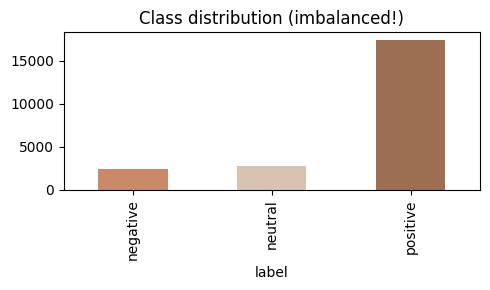

In [5]:
# distribution plot
import matplotlib.pyplot as plt
df["label"].value_counts().reindex(LABEL_NAMES).plot(
    kind="bar", color=["#c98a6a", "#d8c3b3", "#9c6f52"], figsize=(5, 3))
plt.title("Class distribution (imbalanced!)"); plt.tight_layout(); plt.show()


## 3. Split + TF-IDF
Stratified 80/20 split keeps the class proportions in both sets.


In [6]:
#@title 3.1  Split + vectorise { display-mode: "form" }
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["y"], test_size=0.2, random_state=42, stratify=df["y"])

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2),
                        min_df=5, stop_words="english")
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

cw = compute_class_weight("balanced", classes=np.arange(len(LABEL_NAMES)), y=y_train)
sw = np.array([cw[y] for y in y_train])
print("TF-IDF shape:", Xtr.shape, "| class weights:", cw.round(3))


TF-IDF shape: (18112, 10000) | class weights: [3.184 2.674 0.433]


## 4. Train + compare 3 models


In [7]:
#@title 4.1  Train 3 candidates { display-mode: "form" }
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0),
    "Naive Bayes":         MultinomialNB(),
    "Linear SVM":          LinearSVC(),
}
results = {}
for name, clf in candidates.items():
    clf.fit(Xtr, y_train, sample_weight=sw)
    pred = clf.predict(Xte)
    results[name] = (accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"))

res = pd.DataFrame(results, index=["Accuracy", "Macro-F1"]).T
res


,Accuracy,Macro-F1
Logistic Regression,0.801501,0.633089
Naive Bayes,0.773681,0.623393
Linear SVM,0.799514,0.618250


## 5. Winner + detailed report


In [8]:
#@title 5.1  Pick winner + classification report { display-mode: "form" }
from sklearn.metrics import classification_report

best_name = max(results, key=lambda n: (results[n][1], results[n][0]))
best_clf  = candidates[best_name]
w_acc, w_f1 = results[best_name]
print(f"WINNER: {best_name}  (Accuracy={w_acc:.4f}, Macro-F1={w_f1:.4f})")
print(classification_report(y_test, best_clf.predict(Xte),
                            target_names=LABEL_NAMES, digits=4))


WINNER: Logistic Regression  (Accuracy=0.8015, Macro-F1=0.6331)
              precision    recall  f1-score   support

    negative     0.5246    0.6287    0.5720       474
     neutral     0.3557    0.4885    0.4116       565
    positive     0.9595    0.8756    0.9157      3490

    accuracy                         0.8015      4529
   macro avg     0.6133    0.6643    0.6331      4529
weighted avg     0.8387    0.8015    0.8168      4529



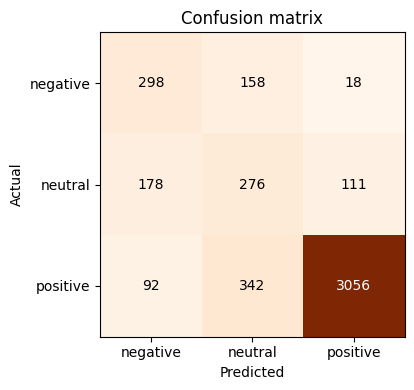

In [9]:
# confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, best_clf.predict(Xte))
fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(cm, cmap="Oranges")
ax.set_xticks(range(3)); ax.set_xticklabels(LABEL_NAMES)
ax.set_yticks(range(3)); ax.set_yticklabels(LABEL_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title("Confusion matrix"); plt.tight_layout(); plt.show()


## 6. Live demo predictions
Try your own sentences - this is exactly what the site's `/sentiment` endpoint returns.


In [10]:
#@title 6.1  Predict sample reviews { display-mode: "form" }
demo_texts = [
    "Absolutely wonderful - silky and sexy and comfortable, loved it!",
    "The material is cheap and ripped after one wash, very disappointed.",
    "It is okay, nothing special, fits fine but the color is a bit off.",
]
preds = best_clf.predict(tfidf.transform(demo_texts))
for t, p in zip(demo_texts, preds):
    print(f"[{LABEL_NAMES[p]:>8}]  {t[:60]}...")


[positive]  Absolutely wonderful - silky and sexy and comfortable, loved...
[negative]  The material is cheap and ripped after one wash, very disapp...
[positive]  It is okay, nothing special, fits fine but the color is a bi...


In [11]:
#@title 6.2  Try YOUR OWN sentence { display-mode: "form" }
MY_TEXT = "Worst product ever, it broke immediately and I want a refund."  #@param {type:"string"}
p = best_clf.predict(tfidf.transform([MY_TEXT]))[0]
print(f"Prediction: {LABEL_NAMES[p]}")


Prediction: negative


## 7. Save model


---
## Save the trained model

The service expects a pickled bundle in `fastapi_ml/models/`. In Colab we save it to `/content/models/`
and offer a download so you can drop it into the repo.


In [12]:
#@title 7.1  Save bundle { display-mode: "form" }
import pickle, os

bundle = {
    "model_type": "logistic_regression",
    "vectorizer": tfidf,
    "classifier": best_clf,
    "label_names": LABEL_NAMES,
    "metrics": {"accuracy": float(w_acc), "macro_f1": float(w_f1)},
}
os.makedirs("/content/models", exist_ok=True)
OUT = "/content/models/sentiment_model.pkl"
with open(OUT, "wb") as f:
    pickle.dump(bundle, f)
print("saved ->", OUT)

try:
    from google.colab import files
    files.download(OUT)
except Exception as e:
    print("Not in Colab, skipping download.", e)


saved -> /content/models/sentiment_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>